In [222]:
# Experiment to test the performance of different IP forward models from MPA and Cole  

import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import numpy as np
import torch

from anemone.experiment import *
from anemone.forwards import *
from anemone.inversion import SmoothModelColeCole, FewLayerColeCole

In [223]:
tx = Loop.square(3)
rx = Receiver(x=13)
waveform = Waveform.example()
recfilter = FilterChain([ButterworthFilter(2.4e5,1),
                         ButterworthFilter(6.2e5,1),
                         ButterworthFilter(4.5e5,1)])

In [224]:
# Define the MPA model characteristics, Transmitter and Receiver size and position
# and the waveform to be used. 
times = torch.logspace(-5, -3, 32)
fwrTD = Forward.mpa(tx, rx, times, filterfunc=recfilter)


frqs = torch.logspace(3,6,51)
fwrFD = ForwardFD.mpa(tx, rx, frqs, filterfunc=recfilter)

In [225]:
# Define the model parameters fopr the MPA model. 


second_layer_rhos = torch.tensor([500, 100, 50, 10], dtype=torch.double)

thickness = torch.tensor([30], dtype=torch.double)

# Ip values for the MPA model in the second layer
phi_max_values = torch.logspace(start=torch.log10(torch.tensor(1)), 
                            end=torch.log10(torch.tensor(1000.0)), 
                            steps=10, dtype=torch.double)/1e3

tau_phi_values = torch.logspace(start=torch.log10(torch.tensor(1e-6)),
                            end=torch.log10(torch.tensor(1e-2)), 
                            steps=10, dtype=torch.double)

c_values = torch.tensor([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9], dtype=torch.double)

phi_2 = torch.tensor(0.001, dtype=torch.double)
tau_phi_2 = 1e-4
c_2 = 0.5

In [226]:
# Define separate colormaps
cmap_c = cm.get_cmap('autumn')
cmap_phi = cm.get_cmap('winter')
cmap_tau = cm.get_cmap('copper')

# Normalize for each parameter
norm_c = mcolors.Normalize(vmin=float(c_values.min()), vmax=float(c_values.max()))
norm_phi = mcolors.Normalize(vmin=float(phi_max_values.min()), vmax=float(phi_max_values.max()))
norm_tau = mcolors.Normalize(vmin=float(tau_phi_values.min()), vmax=float(tau_phi_values.max()))

C:\Users\au653994\AppData\Local\Temp\ipykernel_17512\121952762.py:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_c = cm.get_cmap('autumn')
C:\Users\au653994\AppData\Local\Temp\ipykernel_17512\121952762.py:3: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_phi = cm.get_cmap('winter')
C:\Users\au653994\AppData\Local\Temp\ipykernel_17512\121952762.py:4: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_tau = cm.get_cmap('copper')


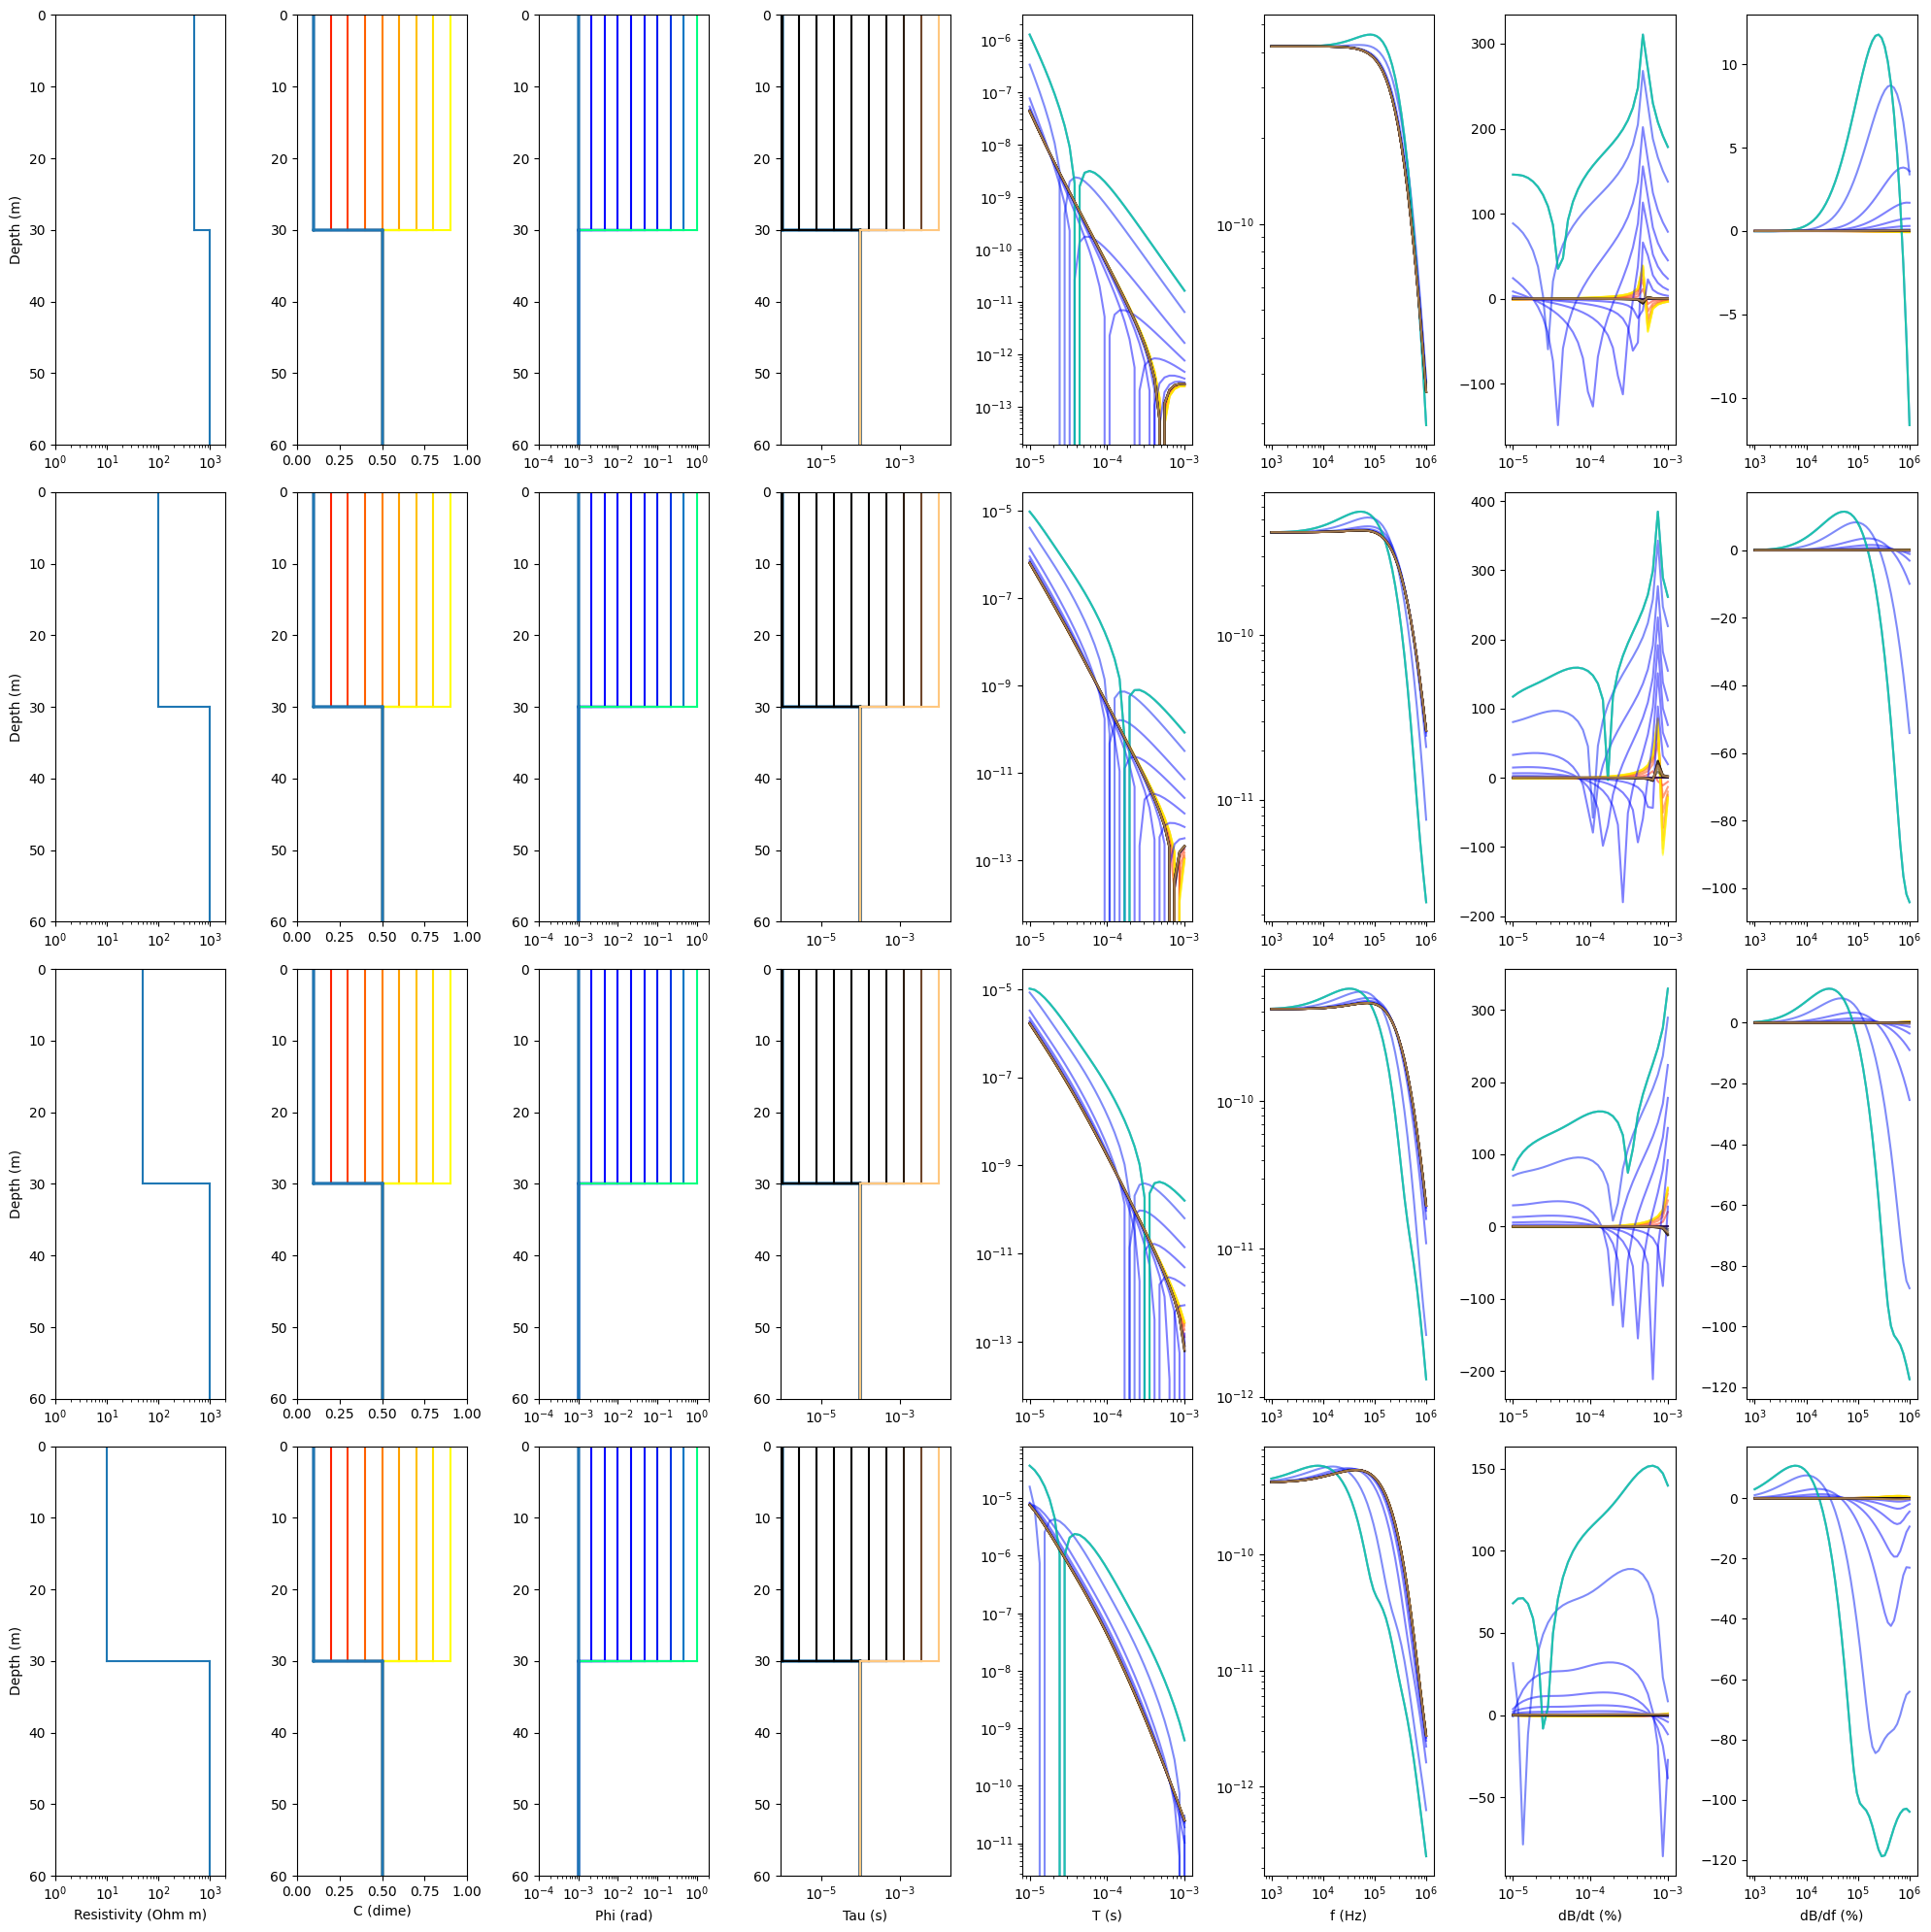

In [227]:
z0 = 0.0
z1 = thickness[0].item()
z2 = 100.0 # Bottom truncation 

n_models = len(second_layer_rhos)

fig,axs = plt.subplots(n_models, 8, figsize=(20, 5*n_models))

rho_l_fixed = 1000; 

for i, rho2 in enumerate(second_layer_rhos):
    rho = torch.tensor([rho2.item(), rho_l_fixed], dtype=torch.double)
    rho_ref = torch.tensor([rho2.item(), rho_l_fixed], dtype=torch.double)
    phi_ref = torch.tensor([phi_max_values[0].item(), phi_2], dtype=torch.double)
    tau_phi_ref = torch.tensor([tau_phi_values[0].item(), tau_phi_2], dtype=torch.double)
    c_ref = torch.tensor([c_values[0].item(), c_2], dtype=torch.double)

    dbdt_ref = fwrTD(rho_ref, phi_ref, tau_phi_ref, c_ref, thickness)
    dbdf_ref = fwrFD(rho_ref, phi_ref, tau_phi_ref, c_ref, thickness)

    axs[i,0].semilogx([rho[0].item(), rho[0].item()], [z0, z1], color='C0', linestyle='-')
    axs[i,0].semilogx([rho[0].item(), rho[1].item()], [z1, z1], color='C0', linestyle='-')
    axs[i,0].semilogx([rho[1].item(), rho[1].item()], [z1, z2], color='C0', linestyle='-')
    axs[i,0].invert_yaxis()
    axs[i,0].set_xlim(1e0, 2e3)
    axs[i,0].set_ylim(60, 0)
    axs[i,0].set_ylabel('Depth (m)')

    # --- Vary C only ---
    for c0 in c_values:
        color = cmap_c(norm_c(c0.item()))
        c = torch.tensor([c0.item(), c_2], dtype=torch.double)
        dbdt = fwrTD(rho, phi_ref, tau_phi_ref, c, thickness)
        dbdf = fwrFD(rho, phi_ref, tau_phi_ref, c, thickness)
        
        # Linear changes
        #pct_dbdt = ((dbdt - dbdt_ref) / dbdt_ref) * 100
        #pct_dbdf = ((dbdf - dbdf_ref) / dbdf_ref) * 100

        # Log scale ratio 
        pct_dbdt = 100 * (torch.log10(torch.abs(dbdt)) - torch.log10(torch.abs(dbdt_ref)))
        pct_dbdf = 100 * (torch.log10(torch.abs(dbdf)) - torch.log10(torch.abs(dbdf_ref)))

        axs[i][4].loglog(times, dbdt, color=color, alpha=0.5)
        axs[i][4].loglog(times, -dbdt, color=color, alpha=0.5)
        axs[i][5].loglog(frqs, torch.abs(dbdf), color=color, alpha=0.5)
        axs[i][6].semilogx(times, pct_dbdt, color=color, alpha=0.5)
        axs[i][7].semilogx(frqs, pct_dbdf, color=color, alpha=0.5)

        # C changes here
        axs[i,1].plot([c0.item(), c0.item()], [z0, z1], color=color, linestyle='-')
        axs[i,1].plot([c0.item(), c_2], [z1, z1], color=color, linestyle='-')
        axs[i,1].plot([c_2, c_2], [z1, z2], color=color, linestyle='-')
        axs[i,1].invert_yaxis()
        #axs[i,1].set_ylim(0, 60)
        axs[i,1].set_xlim(0, 1.0)

        axs[i,2].semilogx([phi_ref[0].item(), phi_ref[0].item()], [z0, z1], color='C0', linestyle='-')
        axs[i,2].semilogx([phi_ref[0].item(), phi_2], [z1, z1], color='C0', linestyle='-')
        axs[i,2].semilogx([phi_2, phi_2], [z1, z2], color='C0', linestyle='-')
        axs[i,2].invert_yaxis()
        #axs[i,1].set_ylim(0, 60)
        axs[i,2].set_xlim(0.1e-3, 2.0)

        axs[i,3].semilogx([tau_phi_ref[0].item(), tau_phi_ref[0].item()], [z0, z1], color='C0', linestyle='-')
        axs[i,3].semilogx([tau_phi_ref[0].item(), tau_phi_2], [z1, z1], color='C0', linestyle='-')
        axs[i,3].semilogx([tau_phi_2, tau_phi_2], [z1, z2], color='C0', linestyle='-')
        axs[i,3].invert_yaxis()
        #axs[i,3].set_ylim(0, 60)
        axs[i,3].set_xlim(0.9e-6, 2e-2)


    for phi0 in phi_max_values:
        color = cmap_phi(norm_phi(phi0.item()))
        phi = torch.tensor([phi0.item(), phi_2.item()], dtype=torch.double)
        dbdt = fwrTD(rho, phi, tau_phi_ref, c_ref, thickness)
        dbdf = fwrFD(rho, phi, tau_phi_ref, c_ref, thickness)

        pct_dbdt = 100 * (torch.log10(torch.abs(dbdt)) - torch.log10(torch.abs(dbdt_ref)))
        pct_dbdf = 100 * (torch.log10(torch.abs(dbdf)) - torch.log10(torch.abs(dbdf_ref)))

        axs[i][4].loglog(times, dbdt, color=color, alpha=0.5)
        axs[i][4].loglog(times, -dbdt, color=color, alpha=0.5)
        axs[i][5].loglog(frqs, torch.abs(dbdf), color=color, alpha=0.5)
        axs[i][6].semilogx(times, pct_dbdt, color=color, alpha=0.5)
        axs[i][7].semilogx(frqs, pct_dbdf, color=color, alpha=0.5)

        # C is constant here
        axs[i,1].plot([c_ref[0].item(), c_ref[0].item()], [z0, z1], color='C0', linestyle='-')
        axs[i,1].plot([c_ref[0].item(), c_ref[1].item()], [z1, z1], color='C0', linestyle='-')
        axs[i,1].plot([c_ref[1].item(), c_ref[1].item()], [z1, z2], color='C0', linestyle='-')
        axs[i,1].invert_yaxis()
        #axs[i,1].set_ylim(0, 60)
        axs[i,1].set_xlim(0, 1.0)

        # phi changes here
        axs[i,2].semilogx([phi0.item(), phi0.item()], [z0, z1], color=color, linestyle='-')
        axs[i,2].semilogx([phi0.item(), phi_2], [z1, z1], color=color, linestyle='-')
        axs[i,2].semilogx([phi_2, phi_2], [z1, z2], color=color, linestyle='-')
        axs[i,2].invert_yaxis()
        #axs[i,2].set_ylim(0, 60)
        axs[i,2].set_xlim(0.1e-3, 2.0)

        # # Taus is constant here
        axs[i,3].semilogx([tau_phi_ref[0].item(), tau_phi_ref[0].item()], [z0, z1], color='C0', linestyle='-')
        axs[i,3].semilogx([tau_phi_ref[0].item(), tau_phi_ref[1].item()], [z1, z1], color='C0', linestyle='-')
        axs[i,3].semilogx([tau_phi_ref[1].item(),tau_phi_ref[1].item()], [z1, z2], color='C0', linestyle='-')
        axs[i,3].invert_yaxis()
        #axs[i,3].set_ylim(0, 60)
        axs[i,3].set_xlim(0.9e-6, 2e-2)

    for tau0 in tau_phi_values:
        color = cmap_tau(norm_tau(tau0.item()))
        tau_phi = torch.tensor([tau0.item(), tau_phi_2], dtype=torch.double)
        dbdt = fwrTD(rho, phi_ref, tau_phi, c_ref, thickness)
        dbdf = fwrFD(rho, phi_ref, tau_phi, c_ref, thickness)

        pct_dbdt = 100 * (torch.log10(torch.abs(dbdt)) - torch.log10(torch.abs(dbdt_ref)))
        pct_dbdf = 100 * (torch.log10(torch.abs(dbdf)) - torch.log10(torch.abs(dbdf_ref)))
        
        axs[i][4].loglog(times, dbdt, color=color, alpha=0.5)
        axs[i][4].loglog(times, -dbdt, color=color, alpha=0.5)
        axs[i][5].loglog(frqs, torch.abs(dbdf), color=color, alpha=0.5)
        axs[i][6].semilogx(times, pct_dbdt, color=color, alpha=0.5)
        axs[i][7].semilogx(frqs, pct_dbdf, color=color, alpha=0.5)

        # C is constant here
        axs[i,1].plot([c_ref[0].item(), c_ref[0].item()], [z0, z1], color='C0', linestyle='-')
        axs[i,1].plot([c_ref[0].item(), c_ref[1].item()], [z1, z1], color='C0', linestyle='-')
        axs[i,1].plot([c_ref[1].item(), c_ref[1].item()], [z1, z2], color='C0', linestyle='-')
        axs[i,1].invert_yaxis()
        axs[i,1].set_ylim( 60, 0)
        axs[i,1].set_xlim(0, 1.0)

        # phi is constant here
        axs[i,2].semilogx([phi_ref[0].item(), phi_ref[0].item()], [z0, z1], color='C0', linestyle='-')
        axs[i,2].semilogx([phi_ref[0].item(), phi_2], [z1, z1], color='C0', linestyle='-')
        axs[i,2].semilogx([phi_2, phi_2], [z1, z2], color='C0', linestyle='-')
        axs[i,2].invert_yaxis()
        axs[i,2].set_ylim(60, 0)
        axs[i,2].set_xlim(0.1e-3, 2.0)

        # Tau changes here
        axs[i,3].semilogx([tau0.item(), tau0.item()], [z0, z1], color=color, linestyle='-')
        axs[i,3].semilogx([tau0.item(), tau_phi_2], [z1, z1], color=color, linestyle='-')
        axs[i,3].semilogx([tau_phi_2, tau_phi_2], [z1, z2], color=color, linestyle='-')
        axs[i,3].invert_yaxis()
        axs[i,3].set_ylim(60, 0)
        axs[i,3].set_xlim(0.9e-6, 2e-2)

axs[3,0].set_xlabel('Resistivity (Ohm m)')
axs[3,1].set_xlabel('C (dime)')
axs[3,2].set_xlabel('Phi (rad)')
axs[3,3].set_xlabel('Tau (s)')
axs[3,4].set_xlabel('T (s)')
axs[3,5].set_xlabel('f (Hz)')
axs[3,6].set_xlabel('dB/dt (%)')    
axs[3,7].set_xlabel('dB/df (%)')
    


plt.tight_layout()
#if savefig:
 #   plt.savefig(r'c:\Users\au653994\OneDrive - Aarhus universitet\Documents\PhD\anemone\Figures\2L_IP_Var\MPA_L2_1000ohm.png', dpi=300, bbox_inches='tight')